# Day 41/100 — WasteSort Mini · Reproducible Material Classification
**Environment / Computer Vision | RealWaste nine-class material classification | Kaggle notebook**

**Objective:** classify the *dominant* material class of an image among **Cardboard, Food Organics, Glass, Metal, Miscellaneous Trash, Paper, Plastic, Textile Trash, Vegetation**, keeping original RealWaste labels. This is a research prototype, **not** an authoritative recycling instruction; multilayer/composite materials are especially ambiguous.

**Data source:** UCI [RealWaste](https://archive.ics.uci.edu/dataset/908/realwaste) (4,752 images; CC BY 4.0 on UCI page). Secondary optional data: [TrashNet](https://github.com/garythung/trashnet), six different classes and different capture domain. Do **not** merge taxonomies automatically. Confirm license details at source before redistribution.

**Pipeline:** directory/label audit → image decode and hash audit → deterministic stratified splits with limitations → HOG+LinearSVC baseline → pretrained MobileNetV3-Small transfer learning (requires accessible cached torchvision weights or internet) → validation-based champion selection → held-out test ONCE → per-class metrics/error gallery → model, inference metadata and reproducibility ZIP.

**Integrity note:** RealWaste has no supplied plant/person/video/source-group IDs. Stratification is **image-level**, not a proven source-independent split. Exact duplicates are group-assigned by SHA256; visual near duplicates inspected for risk. Do not claim zero source leakage or generalization to all scenes.

In [1]:
import os, sys, json, csv, re, random, hashlib, platform, subprocess, warnings
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = False
SEED = 42
random.seed(SEED); np.random.seed(SEED)
OUT=Path('/kaggle/working/day41_wastesort'); OUT.mkdir(parents=True,exist_ok=True)
print('Python:',sys.version.split()[0]);print('Input roots:',list(Path('/kaggle/input').glob('*')))
print('Output:',OUT)

Python: 3.13.16
Input roots: [PosixPath('/kaggle/input/datasets')]
Output: /kaggle/working/day41_wastesort


## 1 · Mount discovery and source provenance
The user's Kaggle Input screenshot shows `realwaste_uci/realwaste-main/RealWaste` and `trashnet_images/dataset-resized` inside an attached dataset. The next cell discovers them recursively rather than assuming Kaggle's dataset slug.

In [2]:
ROOT=Path('/kaggle/input')
if not ROOT.exists():raise RuntimeError('Please run inside a Kaggle notebook with WasteSort Mini attached as Input.')
real_dirs=[p for p in ROOT.rglob('RealWaste') if p.is_dir() and any(q.is_dir() for q in p.iterdir())]
if not real_dirs:raise FileNotFoundError('RealWaste class directory absent under /kaggle/input. Attach WasteSort Mini dataset.')
REAL=sorted(real_dirs,key=lambda p:len(p.parts))[0]
TRASH=next((p for p in ROOT.rglob('dataset-resized') if p.is_dir()),None)
classes=sorted([p.name for p in REAL.iterdir() if p.is_dir()])
EXPECTED={'Cardboard','Food Organics','Glass','Metal','Miscellaneous Trash','Paper','Plastic','Textile Trash','Vegetation'}
if set(classes)!=EXPECTED:raise ValueError(f'RealWaste taxonomy changed: {classes}')
print('RealWaste:',REAL); print('Classes:',classes); print('TrashNet:',TRASH)
SOURCE={'primary':'UCI RealWaste (https://archive.ics.uci.edu/dataset/908/realwaste)', 'secondary':'TrashNet (https://github.com/garythung/trashnet)', 'primary_path':str(REAL),'secondary_path':str(TRASH) if TRASH else None,'retrieved_on_utc':datetime.now(timezone.utc).isoformat(),'license_primary':'CC BY 4.0 as shown by UCI; verify attribution and source holder conditions','license_secondary':'Review original TrashNet license for intended use'}
(OUT/'dataset_provenance.json').write_text(json.dumps(SOURCE,indent=2),encoding='utf-8')

RealWaste: /kaggle/input/datasets/wafabila/wastesort-mini-dataset/realwaste_uci/realwaste-main/RealWaste
Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
TrashNet: /kaggle/input/datasets/wafabila/wastesort-mini-dataset/trashnet_images/dataset-resized


609

## 2 · Label distribution, decode integrity, duplicates and leakage audit
Only readable RGB images will be used. Corrupt files are reported and excluded. Exact content duplicates are identified by pixel SHA256 (after RGB conversion) and assigned to a single split. **Near duplicates are not exhaustively excluded**, and source-group disjointness cannot be proven from this dataset.

Usable 4752 decode failures 0
label
Plastic                921
Metal                  790
Paper                  500
Miscellaneous Trash    495
Cardboard              461
Vegetation             436
Glass                  420
Food Organics          411
Textile Trash          318
Duplicate pixel hashes 0 cross-label duplicate hashes 0


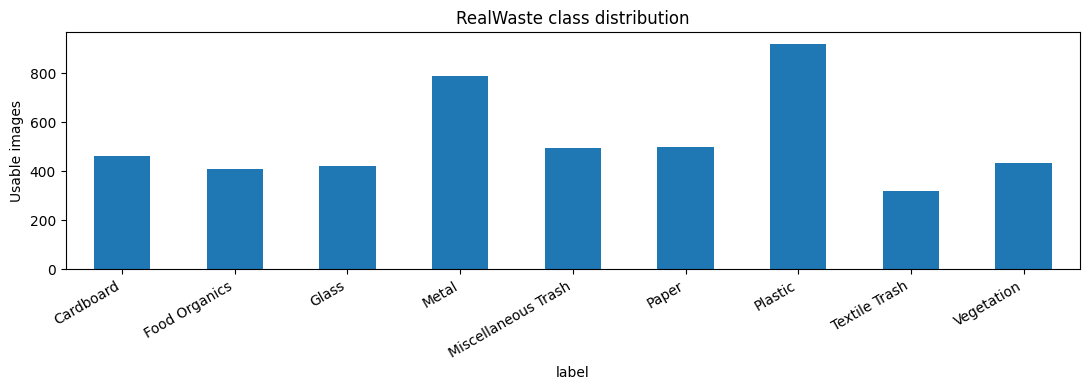

In [3]:
EXT={'.jpg','.jpeg','.png','.webp'}
records=[]; failed=[]
for cls in classes:
    for p in sorted((REAL/cls).rglob('*')):
        if not p.is_file() or p.suffix.lower() not in EXT:continue
        try:
            with Image.open(p) as im:
                rgb=ImageOps.exif_transpose(im).convert('RGB')
                w,h=rgb.size
                if w<32 or h<32:raise ValueError('undersized image')
                px=hashlib.sha256(rgb.tobytes()).hexdigest()
            records.append({'path':str(p),'label':cls,'width':w,'height':h,'pixel_sha256':px})
        except Exception as e:failed.append({'path':str(p),'error':str(e)})
df=pd.DataFrame(records)
if df.empty:raise RuntimeError('No readable RealWaste images')
print('Usable',len(df),'decode failures',len(failed));print(df.label.value_counts().to_string())
if len(df)!=4752:print('[AUDIT WARNING] Expected UCI count 4,752; actual:',len(df))
conflicting=df.groupby('pixel_sha256').label.nunique()
conflicting_hashes=conflicting[conflicting>1].index.tolist()
print('Duplicate pixel hashes',len(df)-df.pixel_sha256.nunique(),'cross-label duplicate hashes',len(conflicting_hashes))
if conflicting_hashes:
    # Cannot safely train on contradictory labels: quarantine all involved hashes
    quarantined=df[df.pixel_sha256.isin(conflicting_hashes)]
    quarantined.to_csv(OUT/'quarantined_conflicting_labels.csv',index=False)
    df=df[~df.pixel_sha256.isin(conflicting_hashes)].reset_index(drop=True)
with (OUT/'decode_failures.json').open('w',encoding='utf-8') as f:json.dump(failed,f,indent=2)
counts=df.label.value_counts().reindex(classes)
fig,ax=plt.subplots(figsize=(11,4));counts.plot.bar(ax=ax);ax.set(ylabel='Usable images',title='RealWaste class distribution');plt.xticks(rotation=30,ha='right');plt.tight_layout();plt.savefig(OUT/'class_distribution.png',dpi=150);plt.show()

## 3 · Defensible splitting and precise limitation
Split *unique pixel hashes*, stratified by class, approximately 70/15/15. Identical pixel contents cannot cross partitions. Held-out test labels will **not** be inspected for model selection. Without source-group or acquisition-session IDs, stronger group-disjoint splitting is impossible to certify; record this explicitly.

In [4]:
from sklearn.model_selection import train_test_split
unique=df.drop_duplicates('pixel_sha256').copy()
# Cross-label duplicates have been quarantined above
train_u,temp_u=train_test_split(unique,test_size=.30,random_state=SEED,stratify=unique.label)
val_u,test_u=train_test_split(temp_u,test_size=.50,random_state=SEED,stratify=temp_u.label)
lookup={h:s for s,d in [('train',train_u),('val',val_u),('test',test_u)] for h in d.pixel_sha256}
df['split']=df.pixel_sha256.map(lookup)
assert df.split.notna().all()
for a,b in [('train','val'),('train','test'),('val','test')]:
    assert not (set(df[df.split==a].pixel_sha256)&set(df[df.split==b].pixel_sha256))
print(pd.crosstab(df.label,df.split).to_string())
print('Samples:',df.split.value_counts().to_dict())
df.to_csv(OUT/'split_manifest.csv',index=False)
(OUT/'leakage_audit.json').write_text(json.dumps({'strategy':'stratified on distinct RGB pixel hashes; all exact RGB duplicate hashes in same split','exact_hash_overlap_across_splits':0,'duplicate_pixel_hash_extra_images':int(len(df)-df.pixel_sha256.nunique()),'conflicting_label_hashes_excluded':len(conflicting_hashes),'source_group_disjoint':'not established (source IDs unavailable)','near_duplicate_audit':'not exhaustive'},indent=2),encoding='utf-8')

split                test  train  val
label                                
Cardboard              69    323   69
Food Organics          62    288   61
Glass                  63    294   63
Metal                 118    553  119
Miscellaneous Trash    75    346   74
Paper                  75    350   75
Plastic               138    645  138
Textile Trash          48    222   48
Vegetation             65    305   66
Samples: {'train': 3326, 'test': 713, 'val': 713}


345

## 4 · Baseline: color/texture HOG + linear SVM
Unlike an HSV-only rule, HOG+LinearSVC can learn shape. It remains an explicitly non-deep-learning baseline and does not use test labels during tuning.

In [5]:
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from joblib import dump

def hog_feature(path):
    with Image.open(path) as im:
        rgb=np.asarray(ImageOps.exif_transpose(im).convert('RGB').resize((96,96)))
    gray=(0.299*rgb[:,:,0]+0.587*rgb[:,:,1]+0.114*rgb[:,:,2])/255.0
    return hog(gray, orientations=9, pixels_per_cell=(8,8),cells_per_block=(2,2),block_norm='L2-Hys')
# Full baseline; HOG CPU may take a few minutes
feature_cache={}
for i,p in enumerate(df.path.unique(),1):
    feature_cache[p]=hog_feature(p)
    if i%1000==0:print('HOG',i,'/',df.path.nunique())
def X(sub):return np.stack([feature_cache[p] for p in sub.path])
tr=df[df.split=='train'];va=df[df.split=='val'];te=df[df.split=='test']
Xtr,Xva=X(tr),X(va)
clf=make_pipeline(StandardScaler(with_mean=False),LinearSVC(C=1,dual='auto',max_iter=5000,random_state=SEED))
clf.fit(Xtr,tr.label)
baseline_val=clf.predict(Xva)
base_score=f1_score(va.label,baseline_val,labels=classes,average='macro',zero_division=0)
print('Baseline validation macro-F1:',round(base_score,4))
dump(clf,OUT/'hog_linearsvc.joblib')

HOG 1000 / 4752
HOG 2000 / 4752
HOG 3000 / 4752
HOG 4000 / 4752
Baseline validation macro-F1: 0.335


['/kaggle/working/day41_wastesort/hog_linearsvc.joblib']

## 5 · Deep champion candidate: MobileNetV3-Small
Use ImageNet-pretrained weights when available. If Kaggle Internet is off and the weights are not cached, stop **instead of silently claiming transfer learning**. GPU is recommended (Notebook Settings → Accelerator GPU). Training checkpoints are selected **by validation macro-F1 only**. Test remains untouched until selection is frozen.

In [6]:
import torch, torchvision
from torch import nn
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
print('torch',torch.__version__,'torchvision',torchvision.__version__)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
print('device',DEVICE)
BATCH=32 if DEVICE=='cuda' else 16
EPOCHS=12
TRAIN_SIZE=224
class ImageTableDataset(Dataset):
    def __init__(self,table,augment=False):
        self.rows=table.reset_index(drop=True)
        aug=[transforms.RandomResizedCrop(TRAIN_SIZE,scale=(.70,1.0)),transforms.RandomHorizontalFlip(),transforms.RandomRotation(12),transforms.ColorJitter(.15,.15,.15,.04)] if augment else [transforms.Resize(256),transforms.CenterCrop(TRAIN_SIZE)]
        self.transform=transforms.Compose(aug+[transforms.ToTensor(),transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
        self.toidx={c:i for i,c in enumerate(classes)}
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        r=self.rows.iloc[i]
        with Image.open(r.path) as im:img=ImageOps.exif_transpose(im).convert('RGB')
        return self.transform(img),self.toidx[r.label]
train_dl=DataLoader(ImageTableDataset(tr,True),batch_size=BATCH,shuffle=True,num_workers=2,pin_memory=DEVICE=='cuda')
val_dl=DataLoader(ImageTableDataset(va),batch_size=BATCH,shuffle=False,num_workers=2,pin_memory=DEVICE=='cuda')
try:
    net=models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
except Exception as exc:
    raise RuntimeError('ImageNet MobileNetV3 weights unavailable. Enable Kaggle Internet or attach a legitimate pretrained torchvision checkpoint; DO NOT claim transfer learning from random initialization.') from exc
net.classifier[3]=nn.Linear(net.classifier[3].in_features,len(classes))
net=net.to(DEVICE)
optimizer=torch.optim.AdamW(net.parameters(),lr=2e-4,weight_decay=1e-4)
loss_fn=nn.CrossEntropyLoss(label_smoothing=.05)
scaler=torch.amp.GradScaler('cuda',enabled=DEVICE=='cuda')
print('Parameters:',sum(p.numel() for p in net.parameters()))

torch 2.11.0+cu130 torchvision 0.26.0+cu130
device cuda
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 96.3MB/s]


Parameters: 1527081


In [7]:
def infer_loader(model,loader):
    model.eval(); ys=[];yp=[];prob=[]
    with torch.inference_mode():
        for x,y in loader:
            logits=model(x.to(DEVICE));pred=logits.softmax(1).cpu().numpy()
            prob.append(pred);ys.extend(y.numpy());yp.extend(pred.argmax(1))
    return np.asarray(ys),np.asarray(yp),np.concatenate(prob)

best_f1=-1;best_epoch=None;history=[]
for ep in range(1,EPOCHS+1):
    net.train();total=0.0;cnt=0
    for x,y in train_dl:
        x=x.to(DEVICE);y=y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda',enabled=DEVICE=='cuda'):
            logits=net(x);loss=loss_fn(logits,y)
        scaler.scale(loss).backward();scaler.step(optimizer);scaler.update()
        total+=loss.item()*len(y);cnt+=len(y)
    y_true,y_pred,_=infer_loader(net,val_dl)
    val_f1=f1_score(y_true,y_pred,labels=list(range(len(classes))),average='macro',zero_division=0)
    history.append({'epoch':ep,'train_loss':total/cnt,'val_macro_f1':float(val_f1),'val_accuracy':float(accuracy_score(y_true,y_pred))})
    print(f'Epoch {ep:02d} loss={total/cnt:.4f} val_macro_F1={val_f1:.4f}')
    if val_f1>best_f1:
        best_f1=float(val_f1);best_epoch=ep
        torch.save({'model':net.state_dict(),'classes':classes,'epoch':ep,'val_macro_f1':best_f1,'pretrained':'IMAGENET1K_V1','input_size':224},OUT/'mobilenetv3_best.pt')
    if ep-best_epoch>=4:
        print('Early stopping: no validation improvement for 4 epochs');break
pd.DataFrame(history).to_csv(OUT/'training_history.csv',index=False)
print('Deep learning best epoch:',best_epoch,'val macro-F1:',best_f1)

Epoch 01 loss=1.3541 val_macro_F1=0.7195
Epoch 02 loss=0.7927 val_macro_F1=0.8196
Epoch 03 loss=0.6566 val_macro_F1=0.8374
Epoch 04 loss=0.5744 val_macro_F1=0.8573
Epoch 05 loss=0.5096 val_macro_F1=0.8648
Epoch 06 loss=0.4979 val_macro_F1=0.8687
Epoch 07 loss=0.4542 val_macro_F1=0.8900
Epoch 08 loss=0.4233 val_macro_F1=0.8677
Epoch 09 loss=0.4111 val_macro_F1=0.8880
Epoch 10 loss=0.3933 val_macro_F1=0.8943
Epoch 11 loss=0.3786 val_macro_F1=0.9024
Epoch 12 loss=0.3677 val_macro_F1=0.9026
Deep learning best epoch: 12 val macro-F1: 0.9025624178119916


## 6 · Champion selection (validation ONLY)
Choose between baseline HOG+LinearSVC and MobileNetV3-Small based on **validation macro-F1**. The held-out test is evaluated once afterwards with the frozen selection. No threshold tuning or repeated model decisions on the test.

In [8]:
champion='MobileNetV3-Small' if best_f1>base_score else 'HOG+LinearSVC'
selection={'baseline_val_macro_f1':float(base_score),'mobilenet_val_macro_f1':float(best_f1),'selected':champion,'rule':'higher validation macro-F1; tie goes to simpler baseline','deep_best_epoch':best_epoch}
(OUT/'champion_selection.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')
print(json.dumps(selection,indent=2))
if champion=='MobileNetV3-Small':
    checkpoint=torch.load(OUT/'mobilenetv3_best.pt',map_location=DEVICE,weights_only=True)
    net.load_state_dict(checkpoint['model'])
    test_dl=DataLoader(ImageTableDataset(te),batch_size=BATCH,shuffle=False,num_workers=2,pin_memory=DEVICE=='cuda')
    yt,yp,probs=infer_loader(net,test_dl)
    pred=[classes[i] for i in yp]
else:
    pred=clf.predict(X(te)).tolist()
    yt=np.array([classes.index(c) for c in te.label])
    yp=np.array([classes.index(c) for c in pred])
    probs=None
acc=accuracy_score(yt,yp);macro=f1_score(yt,yp,average='macro',labels=list(range(len(classes))),zero_division=0)
report=classification_report(yt,yp,labels=list(range(len(classes))),target_names=classes,output_dict=True,zero_division=0)
metrics={'champion':champion,'test_images':len(te),'test_accuracy':float(acc),'test_macro_f1':float(macro),'per_class':report,'NOTE':'image-level stratification with exact RGB duplicate grouping; unknown scene/source dependence'}
(OUT/'heldout_test_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('FINAL held-out test accuracy:',round(acc,4),'macro-F1:',round(macro,4));print(classification_report(yt,yp,labels=list(range(len(classes))),target_names=classes,zero_division=0))

{
  "baseline_val_macro_f1": 0.3350238334379127,
  "mobilenet_val_macro_f1": 0.9025624178119916,
  "selected": "MobileNetV3-Small",
  "rule": "higher validation macro-F1; tie goes to simpler baseline",
  "deep_best_epoch": 12
}
FINAL held-out test accuracy: 0.9018 macro-F1: 0.9103
                     precision    recall  f1-score   support

          Cardboard       0.88      0.91      0.89        69
      Food Organics       0.94      0.98      0.96        62
              Glass       0.92      0.90      0.91        63
              Metal       0.89      0.88      0.89       118
Miscellaneous Trash       0.89      0.83      0.86        75
              Paper       0.96      0.87      0.91        75
            Plastic       0.84      0.89      0.86       138
      Textile Trash       0.94      0.94      0.94        48
         Vegetation       0.98      0.97      0.98        65

           accuracy                           0.90       713
          macro avg       0.91      0.91     

## 7 · Visualization, failure cases and calibration limitation
Confusion matrix is for the actual held-out subset. Confidence from softmax is not automatically calibrated. **Do not treat class predictions as municipal recycling rules.**

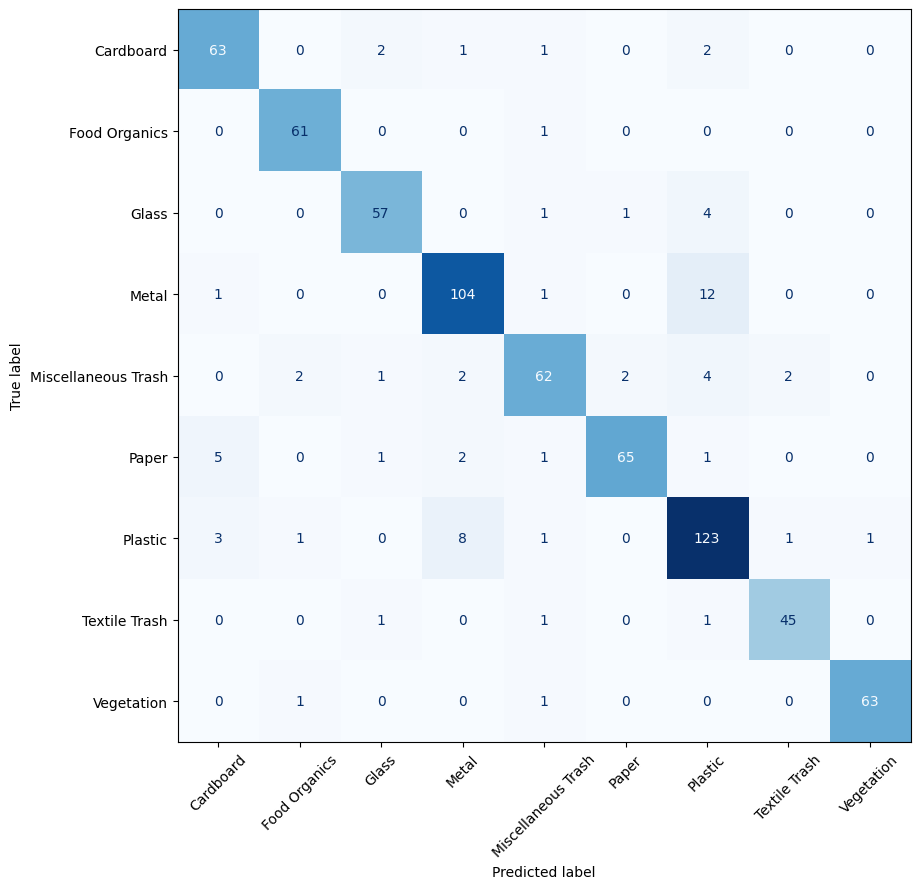

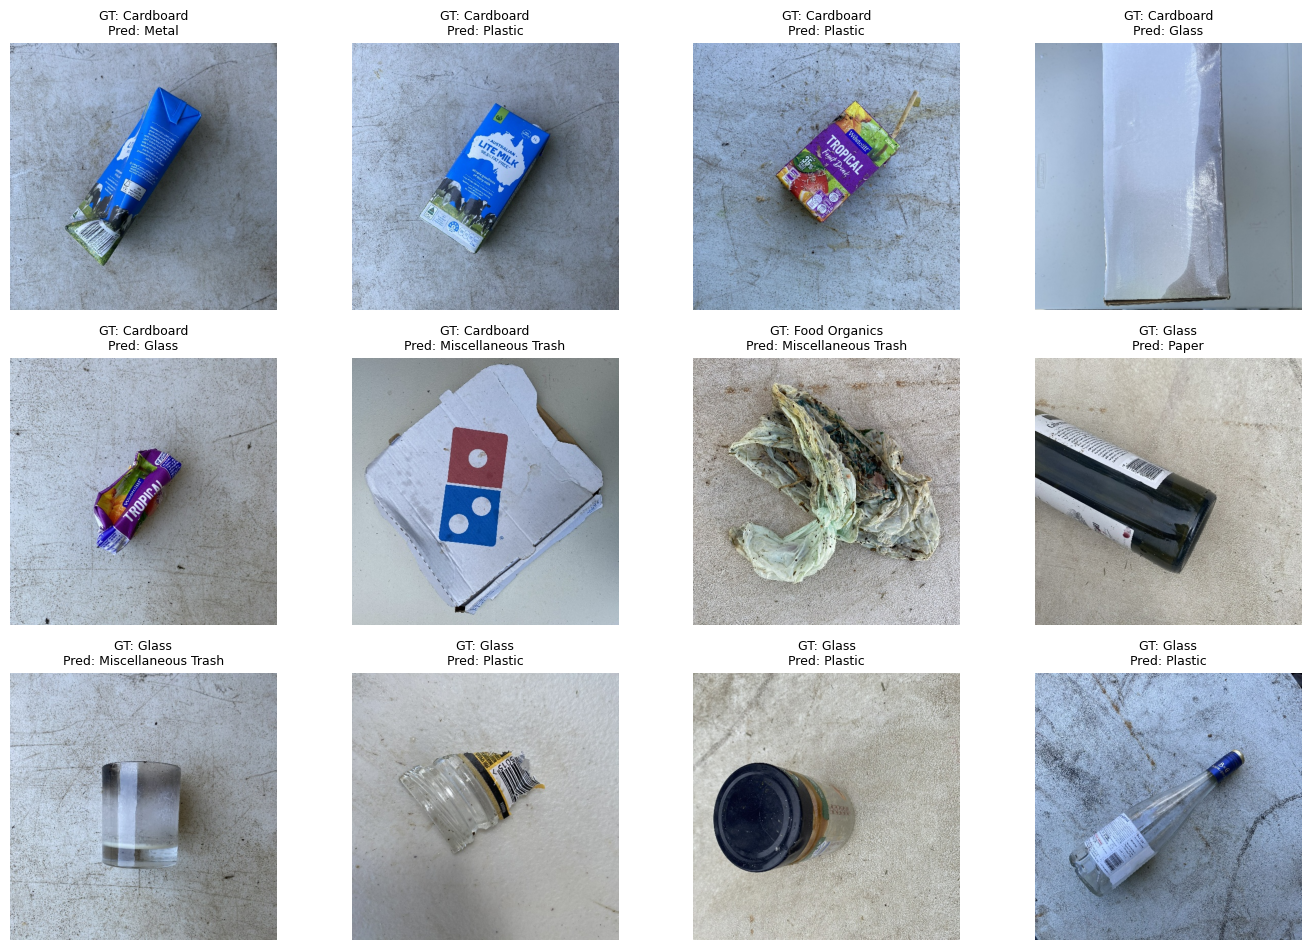

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
cm=confusion_matrix(yt,yp,labels=list(range(len(classes))))
fig,ax=plt.subplots(figsize=(11,9));ConfusionMatrixDisplay(cm,display_labels=classes).plot(ax=ax,xticks_rotation=45,colorbar=False,cmap='Blues');plt.tight_layout();plt.savefig(OUT/'test_confusion_matrix.png',dpi=150);plt.show()
res=te[['path','label','split']].copy().reset_index(drop=True)
res['prediction']=pred;res['correct']=res.label==res.prediction
res.to_csv(OUT/'test_predictions.csv',index=False)
errors=res[~res.correct].head(12)
if not errors.empty:
    cols=4;rows=(len(errors)+cols-1)//cols
    fig,axs=plt.subplots(rows,cols,figsize=(14,rows*3.2));axs=np.array(axs).reshape(-1)
    for ax,(_,r) in zip(axs,errors.iterrows()):
        with Image.open(r.path) as im:ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
        ax.set_title(f"GT: {r.label}\nPred: {r.prediction}", fontsize=9)
        ax.axis('off')
    for ax in axs[len(errors):]:ax.axis('off')
    plt.tight_layout();plt.savefig(OUT/'test_failure_gallery.png',dpi=130);plt.show()
else:print('No held-out errors in this sample (inspect dataset shift anyway).')

## 8 · TrashNet: optional label-aligned external domain check (not used for champion choice)
Common classes in both datasets: cardboard, glass, metal, paper, plastic. **Exclude TrashNet `trash`** because RealWaste `Miscellaneous Trash` is not a verified exact semantic match. No performance on TrashNet can be claimed unless the cell runs successfully. Labels may not be identical in distribution and framing.

In [10]:
if TRASH is None:
    print('[SKIP] TrashNet dataset not attached')
else:
    common={'cardboard':'Cardboard','glass':'Glass','metal':'Metal','paper':'Paper','plastic':'Plastic'}
    aux=[]
    for tc,real_label in common.items():
        for p in sorted((TRASH/tc).glob('*')):
            if p.suffix.lower() not in EXT:continue
            try:
                with Image.open(p) as im:im.verify()
                aux.append({'path':str(p),'label':real_label})
            except Exception:pass
    aux_df=pd.DataFrame(aux)
    if aux_df.empty:print('[SKIP] No readable TrashNet common-class images')
    else:
        # Crucial: this is an out-of-domain check, not an in-domain validation metric
        if champion=='MobileNetV3-Small':
            aux_dl=DataLoader(ImageTableDataset(aux_df),batch_size=BATCH,shuffle=False,num_workers=2)
            a_y,a_p,_=infer_loader(net,aux_dl)
            aux_pred=[classes[i] for i in a_p]
        else:aux_pred=clf.predict(np.stack([hog_feature(p) for p in aux_df.path])).tolist()
        external={'samples':len(aux_df),'five_class_subset_accuracy':float(accuracy_score(aux_df.label,aux_pred)),'fraction_prediction_outside_common_classes':float(np.mean([p not in common.values() for p in aux_pred])),'warning':'5-class subset only; model still predicts 9 classes; TrashNet domain shift and label mapping limitations'}
        (OUT/'trashnet_external_check.json').write_text(json.dumps(external,indent=2),encoding='utf-8')
        print(json.dumps(external,indent=2))

{
  "samples": 2390,
  "five_class_subset_accuracy": 0.35439330543933056,
  "fraction_prediction_outside_common_classes": 0.09163179916317991,
  "warning": "5-class subset only; model still predicts 9 classes; TrashNet domain shift and label mapping limitations"
}


## 9 · Inference contract and artifact export
The MobileNet artifact must be loaded with `torchvision.models.mobilenet_v3_small(weights=None)` and its classifier modified to the saved number of classes before loading its state dict. For HOG use `joblib.load` only with trusted files. Store provenance and version manifest. **No dataset images are exported.**

In [11]:
import zipfile
run={'seed':SEED,'classes':classes,'images_usable':int(len(df)),'split_counts':{k:int(v) for k,v in df.split.value_counts().items()},'realwaste_source':SOURCE['primary'],'trashnet_source':SOURCE['secondary'],'model_champion':champion,'baseline_val_macro_f1':float(base_score),'mobilenet_val_macro_f1':float(best_f1),'final_test_accuracy':float(acc),'final_test_macro_f1':float(macro),'python':platform.python_version(),'torch':torch.__version__,'torchvision':torchvision.__version__,'sklearn':__import__('sklearn').__version__,'cuda':torch.cuda.is_available(),'timestamp_utc':datetime.now(timezone.utc).isoformat(),'limits':['No verified source-group disjointness','RealWaste held-out split is image-level, with exact duplicate grouping','May misclassify compositional/multi-material waste','Predicted material != confirmed recyclability','TrashNet five overlapping classes are optional shifted domain']}
(OUT/'run_manifest.json').write_text(json.dumps(run,indent=2,ensure_ascii=False),encoding='utf-8')
# Avoid raw train images and unnecessary large artifacts in ZIP.
outputs=[p for p in OUT.iterdir() if p.is_file() and p.suffix.lower() in {'.json','.csv','.png','.pt','.joblib'}]
artifact=Path('/kaggle/working/WasteSort_Day41_Artifacts.zip')
with zipfile.ZipFile(artifact,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=3,allowZip64=True) as z:
    for p in outputs:z.write(p,arcname=p.name)
with zipfile.ZipFile(artifact) as z:
    bad=z.testzip()
    assert bad is None,f'CRC failure: {bad}'
print('Artifacts ready:',artifact, 'size MB:',round(artifact.stat().st_size/1024**2,1))
print('Next: Kaggle Save Version -> Save & Run All. Download this ZIP from notebook Output.')

Artifacts ready: /kaggle/working/WasteSort_Day41_Artifacts.zip size MB: 9.0
Next: Kaggle Save Version -> Save & Run All. Download this ZIP from notebook Output.


## 10 · Critical caveats / deployment decision
- **Acceptance**: Train counts, quarantine, split manifests, validation selection, held-out metrics, class F1 and artifacts exist and are reproducible in one Save & Run All execution.
- **Do not silently claim 90%+ accuracy**; actual metrics emerge only after running notebook.
- **Do not train on external TrashNet data** if using it as external test evidence.
- **Image source disjointness** and temporal/geographic generalization unverified. Use controlled out-of-domain evaluation before production.
- **No inference API, authentication, safety guidance, or frontend claims** in this notebook; those are downstream steps.
- **Licensing**: Attribute RealWaste and check TrashNet's source license before publishing examples or data.